In [1]:
# 1 — Importações e Carregamento

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização
plt.style.use('seaborn-v0_8')
plt.rcParams['figure.dpi'] = 100

# Carregar dados
df = pd.read_csv('../data/WineQT.csv')

# Criar variável alvo binária
df['target'] = (df['quality'] >= 7).astype(int)

print(f"✅ Dados carregados: {df.shape[0]} amostras, {df.shape[1]} colunas")
print("\nDistribuição das classes:")
print(df['target'].value_counts(normalize=True).round(3))

✅ Dados carregados: 1143 amostras, 14 colunas

Distribuição das classes:
target
0    0.861
1    0.139
Name: proportion, dtype: float64


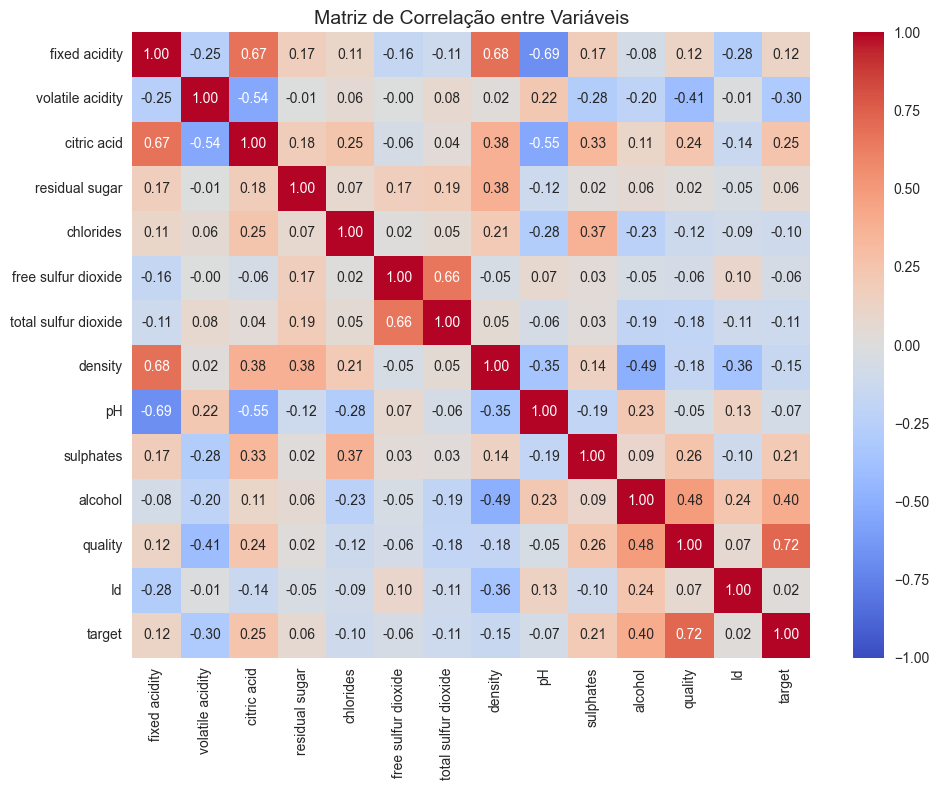

In [2]:
# 2 — Matriz de Correlação

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de Correlação entre Variáveis", fontsize=14)
plt.tight_layout()
plt.savefig('../results/matriz_correlacao.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# 3 — Pré-processamento e Divisão

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separar features e alvo
X = df.drop(columns=['quality', 'target'])
y = df['target']

# Divisão treino/teste com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Padronização
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Treino: {X_train.shape[0]} | Teste: {X_test.shape[0]}")

Treino: 914 | Teste: 229


In [4]:
# 4 — Treinamento dos Modelos

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Modelo 1 — Regressão Logística
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train_scaled, y_train)

# Modelo 2 — Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

print("✅ Modelos treinados!")

✅ Modelos treinados!



📊 Regressão Logística
              precision    recall  f1-score   support

           0      0.900     0.954     0.926       197
           1      0.550     0.344     0.423        32

    accuracy                          0.869       229
   macro avg      0.725     0.649     0.675       229
weighted avg      0.851     0.869     0.856       229

AUC-ROC: 0.847


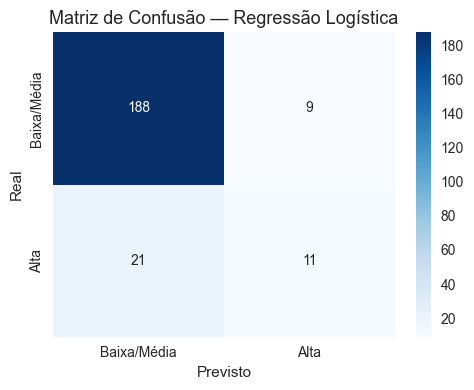


📊 Random Forest
              precision    recall  f1-score   support

           0      0.949     0.949     0.949       197
           1      0.688     0.688     0.688        32

    accuracy                          0.913       229
   macro avg      0.818     0.818     0.818       229
weighted avg      0.913     0.913     0.913       229

AUC-ROC: 0.911


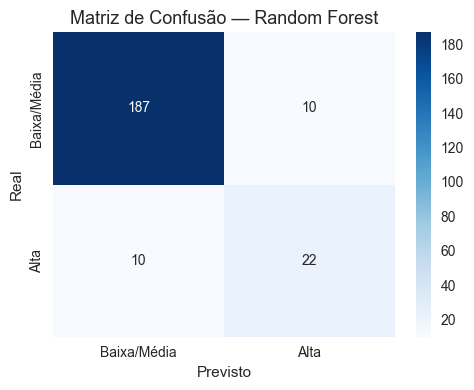

In [5]:
# 5 — Avaliação

def avaliar_modelo(nome, modelo, X_teste, y_teste, eh_escalado=False):
    X_uso = X_test_scaled if eh_escalado else X_teste
    y_pred = modelo.predict(X_uso)
    y_proba = modelo.predict_proba(X_uso)[:, 1]
    
    print(f"\n{'='*50}")
    print(f"📊 {nome}")
    print('='*50)
    print(classification_report(y_teste, y_pred, digits=3))
    print(f"AUC-ROC: {roc_auc_score(y_teste, y_proba):.3f}")
    
    # Matriz de confusão
    cm = confusion_matrix(y_teste, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Baixa/Média', 'Alta'],
                yticklabels=['Baixa/Média', 'Alta'])
    plt.title(f'Matriz de Confusão — {nome}', fontsize=13)
    plt.ylabel('Real')
    plt.xlabel('Previsto')
    plt.tight_layout()
    plt.savefig(f'../results/cm_{nome.lower().replace(" ", "_")}.png', dpi=150)
    plt.show()

avaliar_modelo("Regressão Logística", lr, X_test, y_test, eh_escalado=True)
avaliar_modelo("Random Forest", rf, X_test, y_test, eh_escalado=False)

C:\Users\user\AppData\Local\Temp\ipykernel_4052\2559209475.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias[indices], y=nomes, palette='viridis')


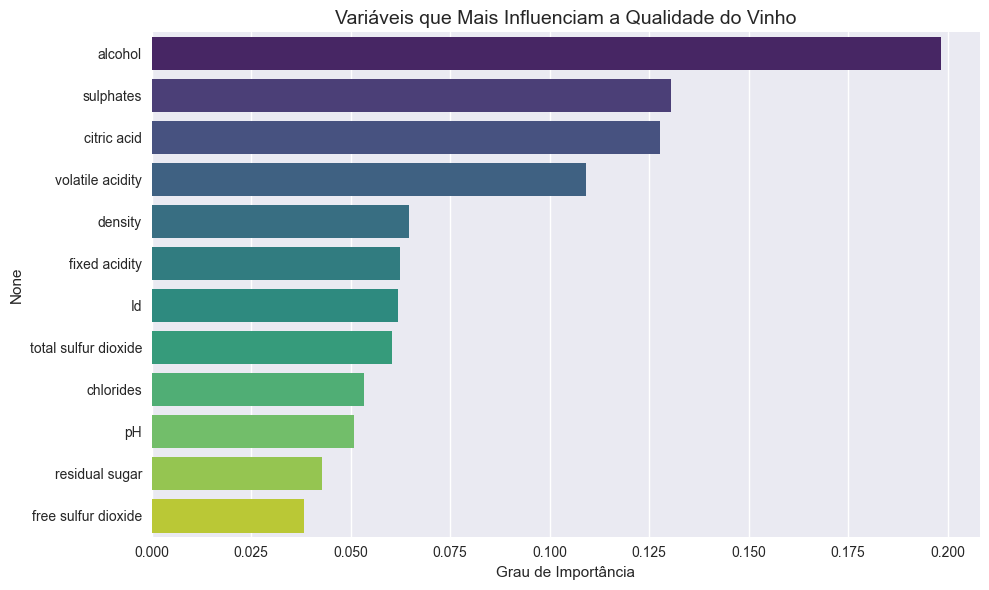

,Variável,Importância
0,alcohol,0.1983
1,sulphates,0.1304
2,citric acid,0.1278
3,volatile acidity,0.1092
4,density,0.0646
5,fixed acidity,0.0623
6,Id,0.0619
7,total sulfur dioxide,0.0605
8,chlorides,0.0532
9,pH,0.0508


In [6]:
# 6 — Importância das Variáveis

# Extrair importância
importancias = rf.feature_importances_
indices = np.argsort(importancias)[::-1]
nomes = X.columns[indices]

# Gráfico
plt.figure(figsize=(10, 6))
sns.barplot(x=importancias[indices], y=nomes, palette='viridis')
plt.title("Variáveis que Mais Influenciam a Qualidade do Vinho", fontsize=14)
plt.xlabel("Grau de Importância", fontsize=11)
plt.tight_layout()
plt.savefig('../results/importancia_variaveis.png', dpi=150, bbox_inches='tight')
plt.show()

# Exibir valores
pd.DataFrame({'Variável': nomes, 'Importância': importancias[indices].round(4)})

In [7]:
# 7 — Conclusão e Recomendações

print("""
====================================================================
                  🍇 RECOMENDAÇÕES PARA A VINÍCOLA
====================================================================

1. 📈 TEOR ALCOÓLICO — Maior impacto POSITIVO
   → Colher uvas no ponto ideal de açúcar para garantir teor alcoólico equilibrado

2. ⚠️ ACIDEZ VOLÁTIL — Maior impacto NEGATIVO
   → Monitorar temperatura e higiene nos tanques de fermentação
   → Evitar proliferação de bactérias que geram ácido acético (vinagre)

3. 🛡️ SULFATOS / SO2 — Proteção essencial
   → Dosagem automatizada para manter níveis ideais de conservação
   → Previne oxidação e preserva sabor e aroma

4. 🎯 Próximos passos
   → Integrar modelo em tempo real nos tanques de produção
   → Expandir base de dados com mais amostras de alta qualidade
====================================================================
""")


                  🍇 RECOMENDAÇÕES PARA A VINÍCOLA

1. 📈 TEOR ALCOÓLICO — Maior impacto POSITIVO
   → Colher uvas no ponto ideal de açúcar para garantir teor alcoólico equilibrado

2. ⚠️ ACIDEZ VOLÁTIL — Maior impacto NEGATIVO
   → Monitorar temperatura e higiene nos tanques de fermentação
   → Evitar proliferação de bactérias que geram ácido acético (vinagre)

3. 🛡️ SULFATOS / SO2 — Proteção essencial
   → Dosagem automatizada para manter níveis ideais de conservação
   → Previne oxidação e preserva sabor e aroma

4. 🎯 Próximos passos
   → Integrar modelo em tempo real nos tanques de produção
   → Expandir base de dados com mais amostras de alta qualidade

